Download the Dataset

In [1]:
import kagglehub, shutil
from pathlib import Path

cache_path = Path(kagglehub.dataset_download("habibulbasher01644/olive-leaf-image-dataset"))
RAW_DIR = Path("../data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)
shutil.copytree(cache_path, RAW_DIR, dirs_exist_ok=True)
print("Done:", RAW_DIR.resolve())

c:\venvs\olive\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 95.5M/95.5M [00:06<00:00, 16.6MB/s]

Extracting files...


Done: C:\Users\user\Desktop\olive-leaf-project\data\raw


Show the data

In [2]:
def tree(path, depth=0, max_depth=3):
    items = sorted(path.iterdir())
    dirs = [i for i in items if i.is_dir()]
    files = [i for i in items if i.is_file()]
    print("  " * depth + f"{path.name}  ({len(files)} files, {len(dirs)} folders)")
    if depth < max_depth:
        for d in dirs: tree(d, depth + 1, max_depth)

tree(RAW_DIR)

raw  (0 files, 1 folders)
  dataset  (0 files, 2 folders)
    test  (0 files, 3 folders)
      aculus_olearius  (200 files, 0 folders)
      Healthy  (220 files, 0 folders)
      olive_peacock_spot  (260 files, 0 folders)
    train  (0 files, 3 folders)
      aculus_olearius  (690 files, 0 folders)
      Healthy  (830 files, 0 folders)
      olive_peacock_spot  (1200 files, 0 folders)


In [3]:
import os, hashlib, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm import tqdm
import cv2

SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme()

DATA_DIR = Path("../data/raw")
OUT_DIR = Path("../outputs"); OUT_DIR.mkdir(exist_ok=True)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
df = pd.DataFrame([
    {"path": str(p), "label": p.parent.name, "split": p.parent.parent.name}
    for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMG_EXT
])

print("Images:", len(df))
pd.crosstab(df["label"], df["split"], margins=True)

Images: 3400


split,test,train,All
label,,,
Healthy,220,830,1050
aculus_olearius,200,690,890
olive_peacock_spot,260,1200,1460
All,680,2720,3400


In [4]:
rows, corrupted = [], []
for p in tqdm(df["path"]):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            rows.append({"path": p, "width": im.width, "height": im.height,
                         "mode": im.mode, "format": im.format,
                         "size_kb": os.path.getsize(p) / 1024})
    except Exception as e:
        corrupted.append((p, str(e)))

df = df.merge(pd.DataFrame(rows), on="path", how="inner")

print("Corrupted files:", len(corrupted))
print("Modes:", df["mode"].value_counts().to_dict())
print("Formats:", df["format"].value_counts().to_dict())
print(df.groupby(["width", "height"]).size())
print(df["size_kb"].describe().round(2))

100%|██████████| 3400/3400 [00:27<00:00, 125.23it/s]

Corrupted files: 0
Modes: {'RGB': 3400}
Formats: {'JPEG': 3400}
width  height
800    600       3400
dtype: int64
count    3400.00
mean       29.50
std         7.04
min        14.00
25%        24.11
50%        28.93
75%        34.10
max        55.46
Name: size_kb, dtype: float64


In [5]:
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = [md5(p) for p in tqdm(df["path"], desc="md5")]

# exact duplicates
dup = df[df.duplicated("md5", keep=False)]
print("Exact duplicate images:", len(dup), "| groups:", dup["md5"].nunique())
print("Redundant copies:", df.duplicated("md5").sum())

# groups with conflicting labels
print("Groups with different labels:", (df.groupby("md5")["label"].nunique() > 1).sum())

# leakage: same image in both train and test
g = df.groupby("md5")["split"].nunique()
leaked = g[g > 1].index
print("Groups in BOTH train and test:", len(leaked))
print("Images involved:", df[df["md5"].isin(leaked)].shape[0])
print("Test images that also exist in train:",
      ((df["split"] == "test") & df["md5"].isin(leaked)).sum())

md5: 100%|██████████| 3400/3400 [00:00<00:00, 8921.66it/s]

Exact duplicate images: 178 | groups: 84
Redundant copies: 94
Groups with different labels: 0
Groups in BOTH train and test: 24
Images involved: 48
Test images that also exist in train: 24


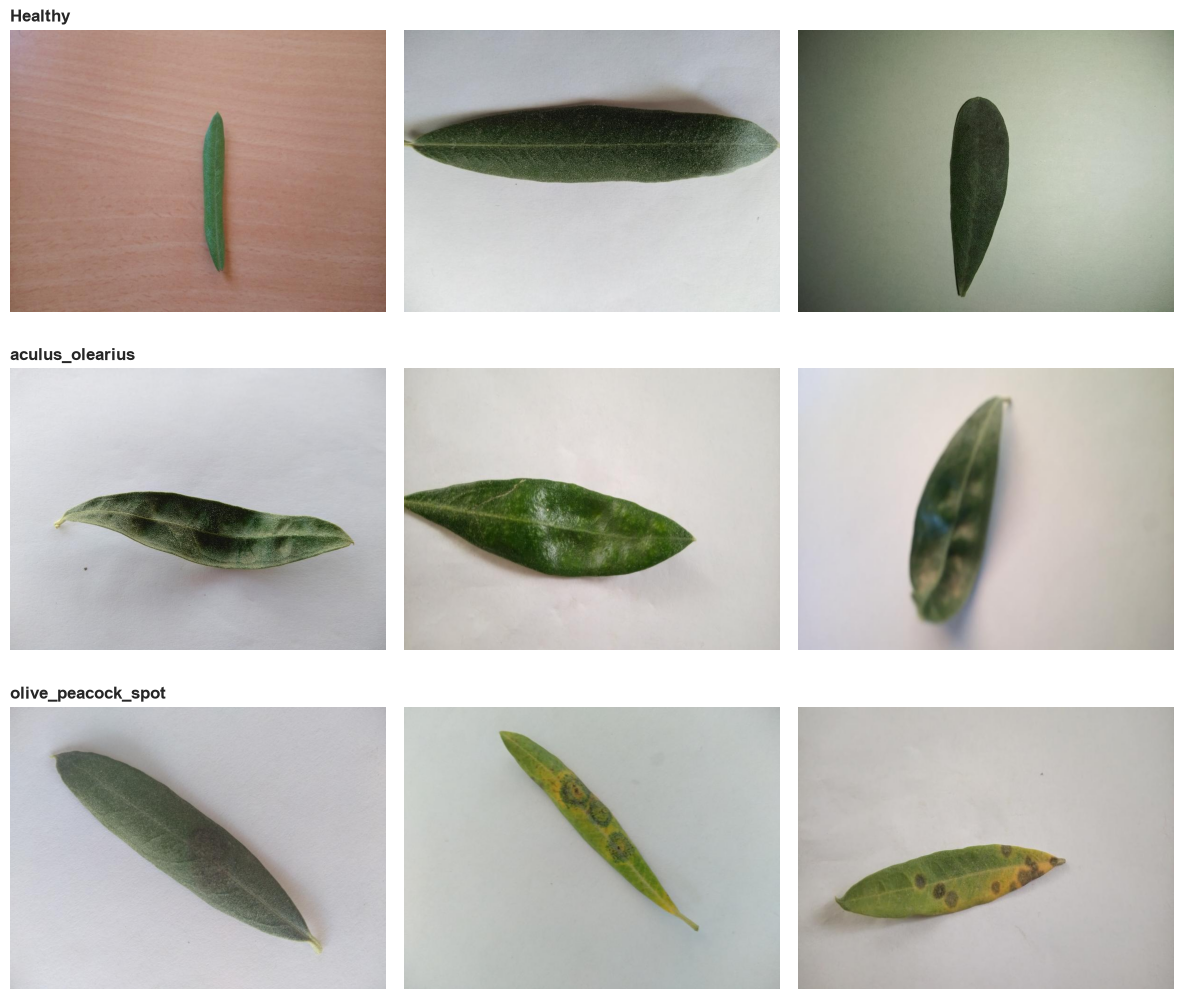

Saved: C:\Users\user\Desktop\olive-leaf-project\outputs\samples.png


In [6]:
classes = sorted(df["label"].unique())
n = 3  # images per class

fig, axes = plt.subplots(len(classes), n, figsize=(4 * n, 3.5 * len(classes)))
for i, c in enumerate(classes):
    sample = df[df["label"] == c].sample(n, random_state=SEED)
    for j in range(n):
        ax = axes[i, j]
        ax.imshow(Image.open(sample.iloc[j]["path"]).convert("RGB"))
        ax.axis("off")
        if j == 0:
            ax.set_title(c, loc="left", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig(OUT_DIR / "samples.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", (OUT_DIR / "samples.png").resolve())

class_distribution

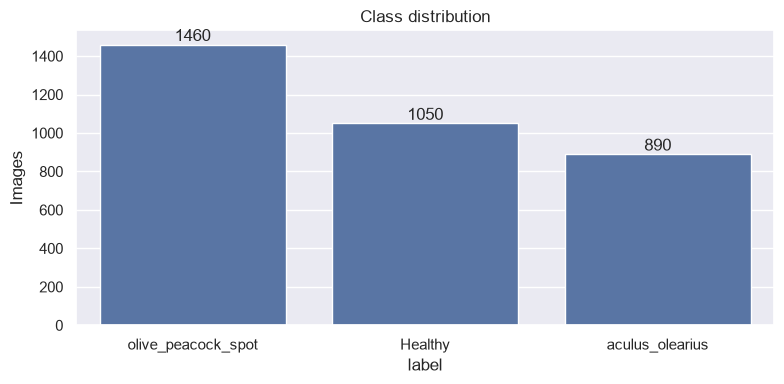

Imbalance ratio: 1.64


In [7]:
counts = df["label"].value_counts()
plt.figure(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values)
for i, v in enumerate(counts.values):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.title("Class distribution"); plt.ylabel("Images")
plt.tight_layout()
plt.savefig(OUT_DIR / "class_distribution.png", dpi=150)
plt.show()
print("Imbalance ratio:", round(counts.max() / counts.min(), 2))

quality

100%|██████████| 3400/3400 [00:04<00:00, 726.03it/s]


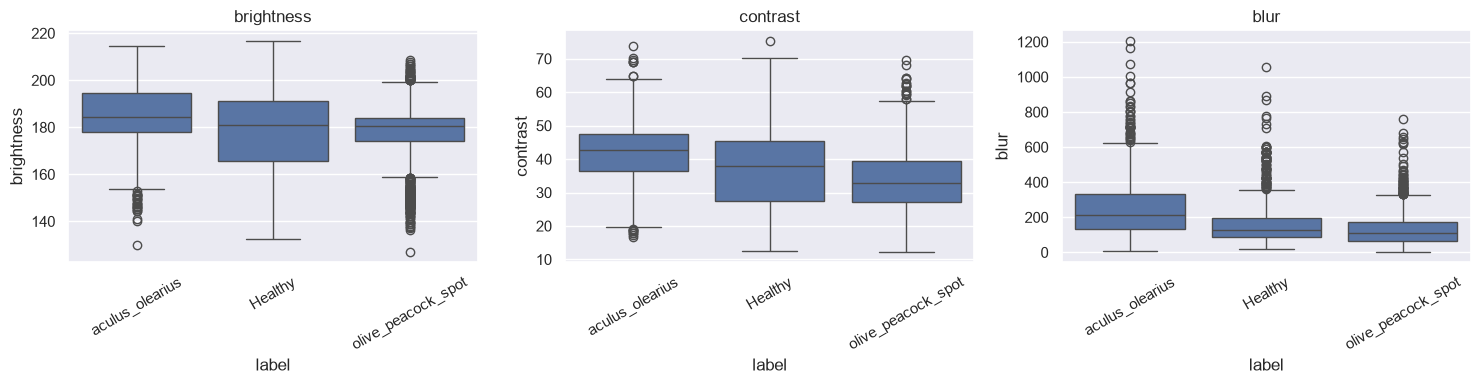

Blurry (blur < 50): 291


In [8]:
def quality(p, size=256):
    g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (size, size))
    return {"brightness": g.mean(), "contrast": g.std(),
            "blur": cv2.Laplacian(g, cv2.CV_64F).var()}

q = pd.DataFrame([quality(p) for p in tqdm(df["path"])])
df = pd.concat([df.reset_index(drop=True), q], axis=1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["brightness", "contrast", "blur"]):
    sns.boxplot(data=df, x="label", y=col, ax=ax)
    ax.tick_params(axis="x", rotation=30); ax.set_title(col)
plt.tight_layout()
plt.savefig(OUT_DIR / "quality.png", dpi=150)
plt.show()
print("Blurry (blur < 50):", (df["blur"] < 50).sum())

In [9]:
df.to_csv(OUT_DIR / "inspection_full.csv", index=False)
print("Saved:", (OUT_DIR / "inspection_full.csv").resolve())

Saved: C:\Users\user\Desktop\olive-leaf-project\outputs\inspection_full.csv
